In [8]:
from common import * 
#loading data into dataframe
df = load_data()
predictor = ["AveRooms"]

# Limit: drop outliers with an unrealistic number of average rooms
max_rooms = 40
df = df[df["AveRooms"] <= max_rooms].reset_index(drop=True)


## Extracting feature and training using polynomail regression

In [31]:

X = df[["AveRooms"]]
y = df["MedHouseVal"]

#Splitting the dataset 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Define polynomial regression degree
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X_train)

#Define and fit the linear regression model with polynomial features
model = LinearRegression()
model.fit(X_poly,y_train)

#Prediction on the test set using the polynomial regression model
X_test_poly = poly.transform(X_test)
y_pred = model.predict(X_test_poly)

#Calculating equation of the polynomial regression line
coefficients = model.coef_
intercept = model.intercept_

#Calculating metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2_test = r2_score(y_test, y_pred)
r2_train = r2_score(y_train, model.predict(X_poly))




## Printing Equation and metrics


In [32]:
print(f"y = {intercept:.4f} {coefficients[1]:+.4f} * X {coefficients[2]:+.4f} * X^2")
print(f"MAE = {mae:.4f} | MSE = {mse:.4f} | R² (test) = {r2_test:.4f} | R² (train) = {r2_train:.4f}")

y = 0.5047 +0.3516 * X -0.0101 * X^2
MAE = 0.8731 | MSE = 1.2310 | R² (test) = 0.0755 | R² (train) = 0.0790


## Scatterplot with regression line


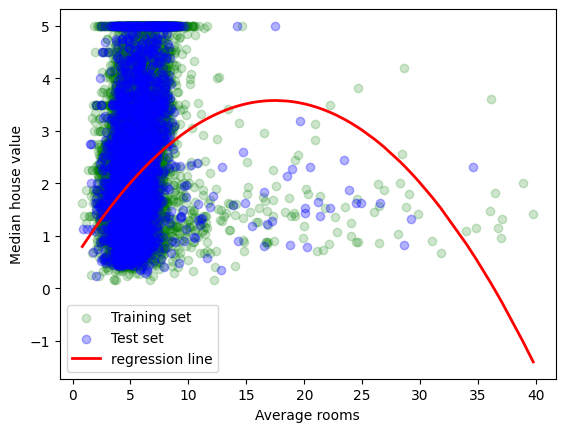

In [35]:
# Scatterplot of training and test sets with the degree-2 polynomial regression line
plt.scatter(X_train["AveRooms"], y_train, color="green", alpha=0.2, label="Training set")
plt.scatter(X_test["AveRooms"], y_test, color="blue", alpha=0.3, label="Test set")

x_values = X["AveRooms"].to_numpy()
sort_order = np.argsort(x_values)
y_plot_pred = model.predict(poly.transform(X))

plt.plot(
    x_values[sort_order],
    y_plot_pred[sort_order],
    color="red",
    linewidth=2,
    label="regression line"
)
plt.xlabel("Average rooms")
plt.ylabel("Median house value")
plt.legend()
plt.show()

## Questions

1. What is the R-squared score of your polynomial regression model on both the training and test sets?

- R² (test) = 0.0755
- R² (train) = 0.0790

2. How do the MAE and MSE values compare with the simple linear regression model?

Recall the values for the linear model: 

MAE = 0.8891 
MSE = 1.2923(exercise 06.02)
The metrics recieved from this training is: 

MAE = 0.8731 
MSE = 1.2310 

The values are a little lower, and thus the model is more precise. About -1.8% for the MAE and -4.74% for the MSE comparing the two trained models, but that is nothing substantial. The MSE and MAE still shows substantial errors - even when polynomial regression is applied.


3. Does the polynomial regression model provide a better fit for the data? Justify your answer based on the plot and metrics.

The metrics (MAE, MSE and R squared) all suggests that the polynomial regression provide a slightly better fit for the data. Especially the R squared becomes better using the polynomial model, where it rises 0.00138 to 0.0755 on the test set. But with an R2 value below 0.1 it still exlains very little of the variance. 

Also from the scatterplot it not easy directly infer if one model is better than the other since the data is still clustered between 2 and 7 (ish) rooms and becomes scattered as average rooms increase. The same problem applies for the simple linear regression, so it is infeasible to infer which model best fits the data based from the scatterplot alone. 

